# PresyoPH – Historical Trends

**Purpose:** Specific Objective 2 of the proposal, "to analyze historical cost-of-living, inflation, and purchasing-power trends", and research question 2, "What are the historical trends in cost-of-living, inflation, and purchasing power in the Philippines?"

**Data:** PSA CPI (2018 = 100) and purchasing power, January 2018 – August 2026; year-on-year inflation, January 2019 – August 2026; and the 2023 FIES. Everything is read through `backend/data.py`, the same functions the dashboard uses, so the numbers here match the dashboard.

**Scope:** descriptive. The analysis reports what changed, when, where, and in which commodity groups. It does not attribute causes, which the data cannot show, and it does not estimate how much each commodity group contributed to overall inflation, which would need PSA's basket weights.

**Sections:**
1. Load the data
2. National trends and phases
3. Purchasing power
4. Commodity groups
5. Regions
6. Household finances (FIES 2023) as context
7. Summary of findings
8. Limitations

Figures are saved to `reports/figures/` (numbers 18–24, continuing from the modeling notebooks).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from app import theme
from backend import data

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.width", 160)

# Same colours as the dashboard (app/theme.py): one per indicator.
COLORS = theme.INDICATOR_COLORS
INK, MUTED = theme.ACTUAL_COLOR, theme.MUTED_COLOR
# Two-part bars (spending + savings): first two slots of the validated categorical palette.
PART_COLORS = ["#2a78d6", "#eb6834"]
# Single-hue sequential ramp (light -> dark blue) for the heatmap.
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# White box behind value labels so reference lines never run through them.
LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=1)

def short(region):
    # "Region V (Bicol Region)" -> "Bicol Region"; "MIMAROPA Region" -> "MIMAROPA"
    return region[region.find("(") + 1:-1] if "(" in region else region.replace(" Region", "")

## 1. Load the data

In [2]:
cpi = data.get_cpi().set_index("date")["value"]
inf = data.get_inflation().set_index("date")["value"]
pp = data.get_purchasing_power().set_index("date")["value"]

for name, s in [("CPI", cpi), ("Inflation", inf), ("Purchasing power", pp)]:
    print(f"{name:<17} {len(s):>3} months  {s.index.min():%b %Y} – {s.index.max():%b %Y}  missing: {s.isna().sum()}")

CPI               104 months  Jan 2018 – Aug 2026  missing: 0
Inflation          92 months  Jan 2019 – Aug 2026  missing: 0
Purchasing power  104 months  Jan 2018 – Aug 2026  missing: 0


## 2. National trends and phases

### 2.1 Year by year

2026 covers January–August only. Inflation starts in 2019 because PSA's year-on-year series in this dataset starts then.

In [3]:
by_year = lambda s: s.groupby(s.index.year)
annual = pd.DataFrame({
    "CPI, average": by_year(cpi).mean(),
    "Inflation, average (%)": by_year(inf).mean(),
    "Inflation, highest (%)": by_year(inf).max(),
    "Inflation, lowest (%)": by_year(inf).min(),
    "Purchasing power, last month": by_year(pp).last(),
})
annual.index.name = "year"
annual

,"CPI, average","Inflation, average (%)","Inflation, highest (%)","Inflation, lowest (%)","Purchasing power, last month"
year,,,,,
2018,99.98,NaN,NaN,NaN,0.99
2019,102.38,2.42,4.40,0.50,0.96
2020,104.83,2.40,3.30,1.60,0.93
2021,108.94,3.92,4.40,3.10,0.90
2022,115.28,5.82,8.10,3.00,0.84
2023,122.17,6.00,8.70,3.90,0.81
2024,126.10,3.22,4.40,1.90,0.78
2025,128.19,1.67,2.90,0.90,0.77
2026,134.38,5.15,7.20,2.00,0.73


In [4]:
cpi_stats = data.get_period_stats("cpi")
print(f"CPI: {cpi_stats['first']:.1f} (Jan 2018) -> {cpi_stats['last']:.1f} (Aug 2026), "
      f"+{cpi_stats['percent_change']:.1f}% in {cpi_stats['months']} months")
print(f"Inflation: highest {inf.max():.1f}% ({inf.idxmax():%b %Y}), lowest {inf.min():.1f}% ({inf.idxmin():%b %Y}), "
      f"average {inf.mean():.2f}%")
print(f"Years with average inflation above 4%: {[y for y, v in annual['Inflation, average (%)'].items() if v > 4]}")

CPI: 97.2 (Jan 2018) -> 136.4 (Aug 2026), +40.3% in 104 months
Inflation: highest 8.7% (Jan 2023), lowest 0.5% (Sep 2019), average 3.77%
Years with average inflation above 4%: [2022, 2023, 2026]


### 2.2 Phases

Inflation's turning points split the period into five phases. The boundaries are the lowest and highest months (September 2019, January 2023, July 2025); they are a reading of the series, not an official PSA classification.

In [5]:
PHASES = {
    "1. Easing": ("2019-01", "2019-09"),
    "2. Low to moderate": ("2019-10", "2021-12"),
    "3. Surge": ("2022-01", "2023-01"),
    "4. Easing": ("2023-02", "2025-07"),
    "5. Renewed rise": ("2025-08", "2026-08"),
}

def phase_table(s):
    rows = []
    for name, (start, end) in PHASES.items():
        seg = s[start:end]
        rows.append({
            "phase": name, "from": f"{seg.index[0]:%b %Y}", "to": f"{seg.index[-1]:%b %Y}", "months": len(seg),
            "first (%)": seg.iloc[0], "last (%)": seg.iloc[-1], "average (%)": seg.mean(),
            "highest (%)": seg.max(), "highest in": f"{seg.idxmax():%b %Y}",
            "lowest (%)": seg.min(), "lowest in": f"{seg.idxmin():%b %Y}",
        })
    return pd.DataFrame(rows).set_index("phase")

phases = phase_table(inf)
phases

,from,to,months,first (%),last (%),average (%),highest (%),highest in,lowest (%),lowest in
phase,,,,,,,,,,
1. Easing,Jan 2019,Sep 2019,9,4.40,0.50,2.76,4.40,Jan 2019,0.50,Sep 2019
2. Low to moderate,Oct 2019,Dec 2021,27,0.60,3.10,2.96,4.40,Aug 2021,0.60,Oct 2019
3. Surge,Jan 2022,Jan 2023,13,3.00,8.70,6.04,8.70,Jan 2023,3.00,Jan 2022
4. Easing,Feb 2023,Jul 2025,30,8.60,0.90,3.79,8.60,Feb 2023,0.90,Jul 2025
5. Renewed rise,Aug 2025,Aug 2026,13,1.50,6.10,3.80,7.20,Apr 2026,1.50,Aug 2025


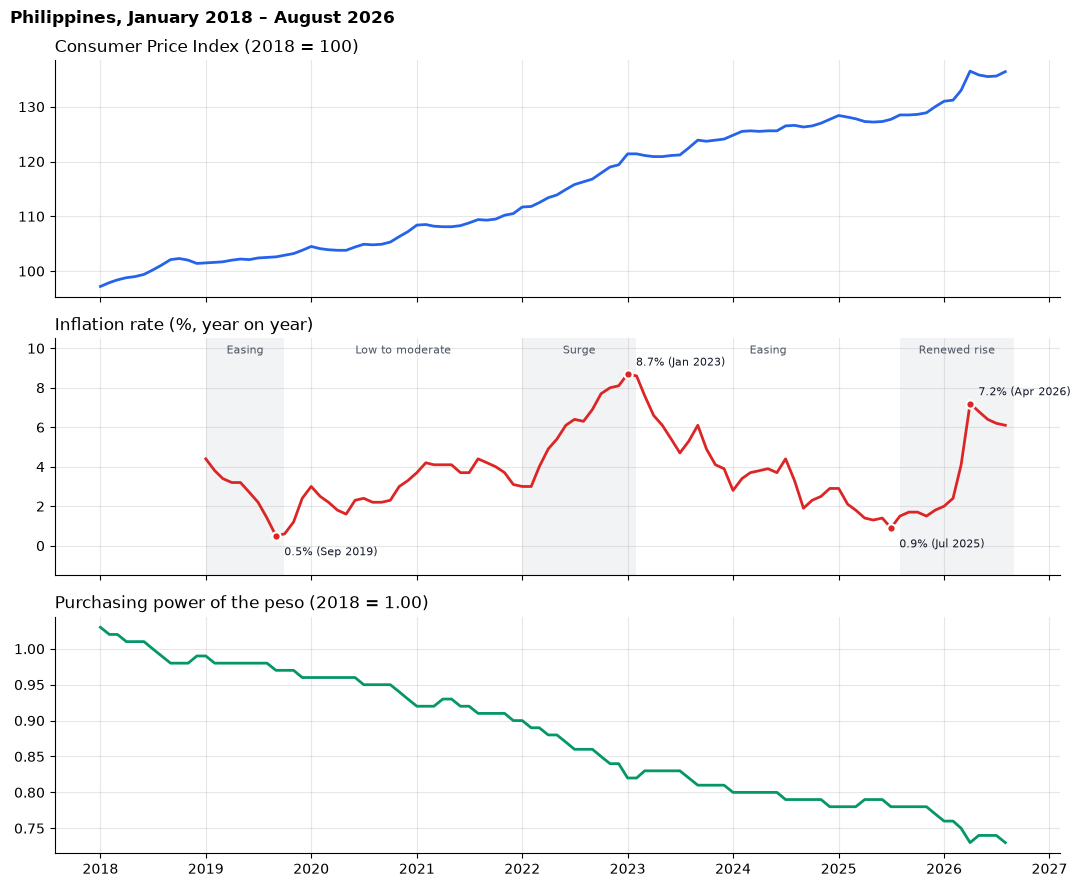

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

axes[0].plot(cpi.index, cpi, color=COLORS["cpi"])
axes[0].set_title("Consumer Price Index (2018 = 100)", loc="left")

ax = axes[1]
for i, (name, (start, end)) in enumerate(PHASES.items()):
    left, right = pd.Timestamp(start), pd.Timestamp(end) + pd.offsets.MonthEnd(0)
    if i % 2 == 0:
        ax.axvspan(left, right, color=MUTED, alpha=0.12, lw=0)
    ax.text(left + (right - left) / 2, 9.6, name.split(". ")[1], ha="center", va="bottom", fontsize=8, color="#4B5563")
ax.plot(inf.index, inf, color=COLORS["inflation"])
for date in [inf.idxmax(), inf["2019"].idxmin(), inf["2023-02":"2025-12"].idxmin(), inf["2026"].idxmax()]:
    v = inf[date]
    ax.plot(date, v, "o", color=COLORS["inflation"], ms=6, mec="white", mew=1.5)
    ax.annotate(f"{v:.1f}% ({date:%b %Y})", (date, v), xytext=(6, 6 if v > 3 else -14),
                textcoords="offset points", fontsize=8, color=INK)
ax.set_ylim(-1.5, 10.5)
ax.set_title("Inflation rate (%, year on year)", loc="left")

axes[2].plot(pp.index, pp, color=COLORS["purchasing_power"])
axes[2].set_title("Purchasing power of the peso (2018 = 1.00)", loc="left")

fig.suptitle("Philippines, January 2018 – August 2026", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "18_national_trends")

## 3. Purchasing power

PSA calculates purchasing power from CPI (1 ÷ CPI × 100), so it moves opposite to prices: a value of 0.73 means a peso buys what ₱0.73 bought in 2018.

In [7]:
pp_2018 = pp["2018"].mean()
print(f"2018 average: {pp_2018:.2f}   Jan 2018: {pp.iloc[0]:.2f}   Aug 2026: {pp.iloc[-1]:.2f}")
print(f"Loss since 2018 (2018 = 1.00): {(1 - pp.iloc[-1]) * 100:.0f}%")
print(f"Loss since Jan 2018: {(1 - pp.iloc[-1] / pp.iloc[0]) * 100:.1f}%")

yearly_loss = (by_year(pp).last().pct_change() * 100).dropna()
print("\nChange over each year (last month vs. previous year's last month, %):")
print(yearly_loss.round(1).to_string())

2018 average: 1.00   Jan 2018: 1.03   Aug 2026: 0.73
Loss since 2018 (2018 = 1.00): 27%
Loss since Jan 2018: 29.1%

Change over each year (last month vs. previous year's last month, %):
date
2019   -3.00
2020   -3.10
2021   -3.20
2022   -6.70
2023   -3.60
2024   -3.70
2025   -1.30
2026   -5.20


## 4. Commodity groups

PSA publishes CPI and inflation for 13 commodity groups. Without the basket weights, the analysis can say which groups' prices rose most, but not how much each one added to overall inflation.

In [8]:
cats = data.list_categories()
labels = dict(zip(cats["item"], cats["label"]))
cat_cpi = data.get_series_wide("cpi", items=cats["item"].tolist()).rename(columns=labels)
cat_inf = data.get_series_wide("inflation", items=cats["item"].tolist()).rename(columns=labels)

all_items_rise = (cpi.iloc[-1] / cpi.iloc[0] - 1) * 100
cat_rise = ((cat_cpi.iloc[-1] / cat_cpi.iloc[0] - 1) * 100).sort_values(ascending=False)
cat_summary = pd.DataFrame({
    "CPI, Aug 2026": cat_cpi.iloc[-1],
    "price rise since Jan 2018 (%)": cat_rise,
    "average inflation 2019–2026 (%)": cat_inf.mean(),
    "highest inflation (%)": cat_inf.max(),
    "highest in": cat_inf.idxmax().dt.strftime("%b %Y"),
}).loc[cat_rise.index]
print(f"All items: +{all_items_rise:.1f}% since Jan 2018")
cat_summary

All items: +40.3% since Jan 2018


,"CPI, Aug 2026",price rise since Jan 2018 (%),average inflation 2019–2026 (%),highest inflation (%),highest in
Alcoholic beverages and tobacco,196.30,113.37,8.79,18.40,Jul 2020
Transport,146.70,51.55,4.49,21.40,Apr 2026
Restaurants and accommodation services,140.70,44.75,4.13,8.60,Apr 2023
Financial services,142.40,42.40,5.57,43.30,Apr 2021
Food and non-alcoholic beverages,137.60,41.71,4.03,10.80,Feb 2023
"Housing, water, electricity, gas and other fuels",133.20,37.46,3.32,8.60,Jan 2023
Health,133.20,35.50,3.43,5.00,Aug 2026
"Furnishings, household equipment and maintenance",129.90,31.88,3.19,6.20,Feb 2023
Personal care and miscellaneous goods and services,128.30,29.86,3.04,5.80,Jun 2023
Education services,125.80,28.76,2.88,6.10,Jul 2024


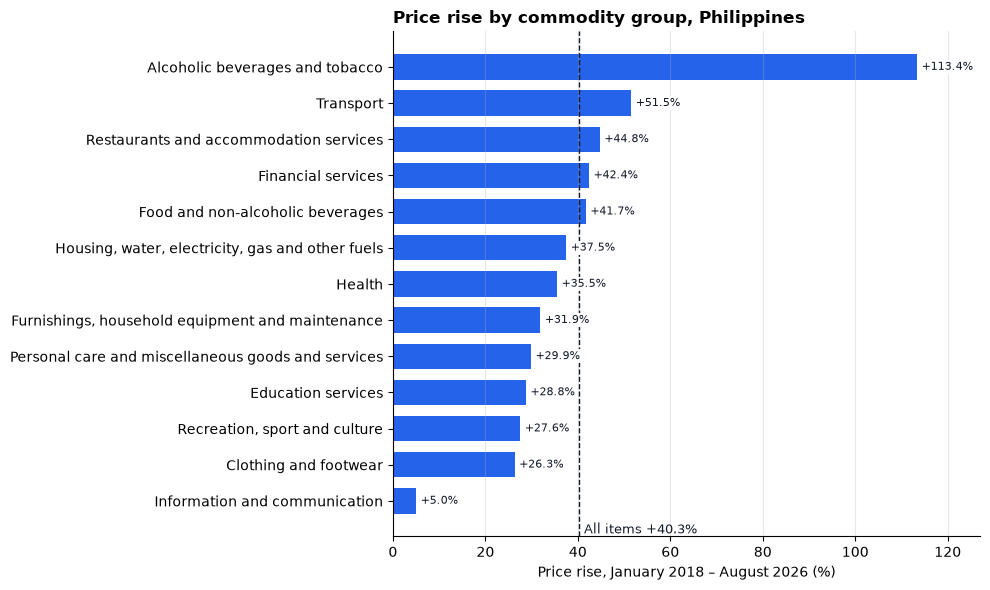

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
order = cat_rise.sort_values()
bars = ax.barh(order.index, order.values, color=COLORS["cpi"], height=0.7)
ax.axvline(all_items_rise, color=INK, ls="--", lw=1)
ax.text(all_items_rise + 1, -0.9, f"All items +{all_items_rise:.1f}%", fontsize=9, color=INK)
for bar, v in zip(bars, order.values):
    ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f"+{v:.1f}%", va="center", fontsize=8, color=INK, bbox=LABEL_BOX)
ax.set_xlabel("Price rise, January 2018 – August 2026 (%)")
ax.set_title("Price rise by commodity group, Philippines", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, order.max() * 1.12)
fig.tight_layout()
save(fig, "19_category_price_rise")

### 4.1 Which groups ran hottest in each phase

Average year-on-year inflation of each group within the phases from section 2.2.

In [10]:
by_phase = pd.DataFrame({name: cat_inf[start:end].mean() for name, (start, end) in PHASES.items()})
by_phase.loc["All items"] = [inf[start:end].mean() for start, end in PHASES.values()]
by_phase.sort_values("3. Surge", ascending=False)

,1. Easing,2. Low to moderate,3. Surge,4. Easing,5. Renewed rise
Transport,1.46,4.92,12.74,0.44,6.83
Financial services,0.00,14.43,9.99,-0.24,0.00
Alcoholic beverages and tobacco,10.48,13.01,8.14,6.65,4.42
"Housing, water, electricity, gas and other fuels",2.96,1.58,6.55,2.90,4.92
Food and non-alcoholic beverages,2.23,3.16,6.24,4.93,2.80
All items,2.76,2.96,6.04,3.79,3.80
Restaurants and accommodation services,3.80,2.79,4.33,5.18,4.52
"Furnishings, household equipment and maintenance",2.99,2.66,3.35,3.75,2.96
Personal care and miscellaneous goods and services,2.40,2.33,3.15,3.87,2.95
Clothing and footwear,2.59,2.14,2.72,3.45,2.43


In [11]:
jump = (cat_inf.loc["2026-04-01"] - cat_inf.loc["2026-03-01"]).sort_values(ascending=False)
print(f"All items: {inf['2026-03-01']:.1f}% (Mar 2026) -> {inf['2026-04-01']:.1f}% (Apr 2026)\n")
pd.DataFrame({"Mar 2026 (%)": cat_inf.loc["2026-03-01"], "Apr 2026 (%)": cat_inf.loc["2026-04-01"],
              "change (points)": jump}).loc[jump.index]

All items: 4.1% (Mar 2026) -> 7.2% (Apr 2026)



,Mar 2026 (%),Apr 2026 (%),change (points)
Transport,9.90,21.40,11.50
"Housing, water, electricity, gas and other fuels",4.70,8.20,3.50
Food and non-alcoholic beverages,2.90,6.00,3.10
Alcoholic beverages and tobacco,3.70,4.80,1.10
Restaurants and accommodation services,5.00,6.00,1.00
Personal care and miscellaneous goods and services,2.90,3.30,0.40
"Furnishings, household equipment and maintenance",3.10,3.50,0.40
Health,3.40,3.80,0.40
"Recreation, sport and culture",4.70,4.90,0.20
Information and communication,0.70,0.90,0.20


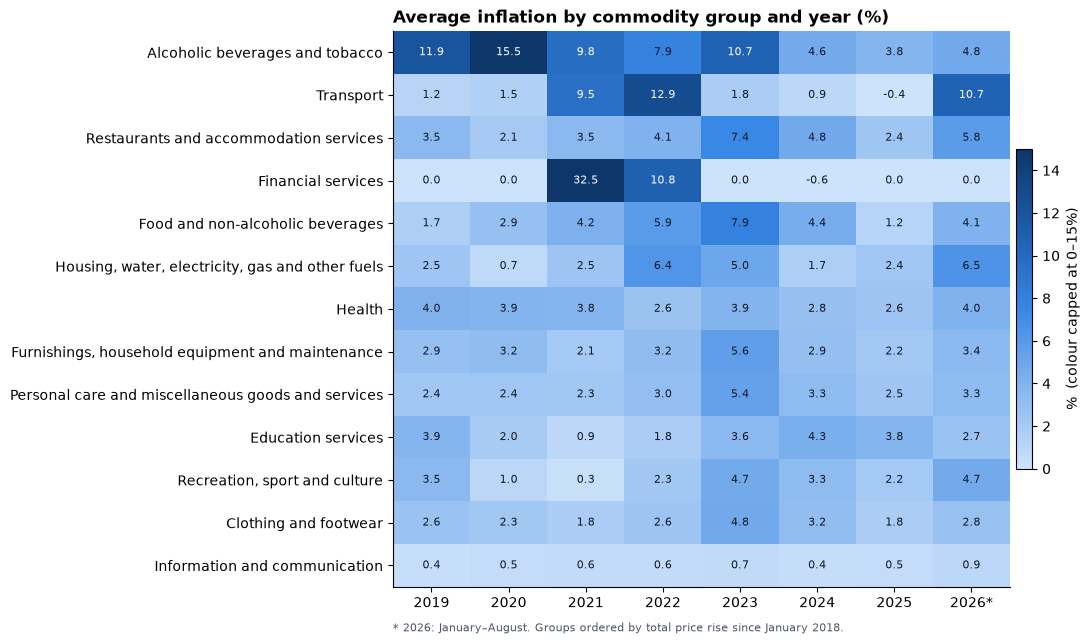

In [12]:
annual_cat = cat_inf.groupby(cat_inf.index.year).mean().T
annual_cat = annual_cat.loc[cat_rise.index]

# Colour is capped at 15% so financial services' one-off 2021 jump (32.5%) does not
# wash out the rest; every cell's exact value is printed on it.
CAP = 15
fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(annual_cat.clip(lower=0, upper=CAP), cmap=BLUES, aspect="auto", vmin=0, vmax=CAP)
ax.set_xticks(range(annual_cat.shape[1]), [str(y) + ("*" if y == 2026 else "") for y in annual_cat.columns])
ax.set_yticks(range(annual_cat.shape[0]), annual_cat.index)
ax.grid(False)
threshold = CAP * 0.55
for (r, c), v in np.ndenumerate(annual_cat.values):
    ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=8,
            color="white" if v > threshold else INK)
ax.set_title("Average inflation by commodity group and year (%)", loc="left", fontweight="bold")
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cbar.set_label(f"%  (colour capped at 0–{CAP}%)")
ax.text(0, -0.08, "* 2026: January–August. Groups ordered by total price rise since January 2018.",
        transform=ax.transAxes, fontsize=8, color="#4B5563")
fig.tight_layout()
save(fig, "20_category_inflation_heatmap")

## 5. Regions

Each region's CPI is indexed to its own 2018 level (2018 = 100), so the indices show **how much prices changed** in each region, not which region is more expensive.

In [13]:
regions = data.list_areas("region")
areas = regions + ["PHILIPPINES"]
reg_cpi = data.get_series_wide("cpi", areas=areas)
reg_inf = data.get_series_wide("inflation", areas=areas)
reg_pp = data.get_series_wide("purchasing_power", areas=areas)

ranks = reg_inf[regions].rank(axis=1, ascending=False, method="min")
reg_summary = pd.DataFrame({
    "price rise since Jan 2018 (%)": (reg_cpi.iloc[-1] / reg_cpi.iloc[0] - 1) * 100,
    "average inflation (%)": reg_inf.mean(),
    "highest inflation (%)": reg_inf.max(),
    "highest in": reg_inf.idxmax().dt.strftime("%b %Y"),
    "inflation Aug 2026 (%)": reg_inf.iloc[-1],
    "purchasing power Aug 2026": reg_pp.iloc[-1],
    "months in top 3": (ranks <= 3).sum(),
    "months in bottom 3": (ranks >= len(regions) - 2).sum(),
}).sort_values("price rise since Jan 2018 (%)", ascending=False)
reg_summary.index = [short(a) if a != "PHILIPPINES" else "PHILIPPINES" for a in reg_summary.index]
reg_summary

,price rise since Jan 2018 (%),average inflation (%),highest inflation (%),highest in,inflation Aug 2026 (%),purchasing power Aug 2026,months in top 3,months in bottom 3
Bicol Region,47.43,4.36,8.80,Feb 2023,7.70,0.70,27.00,1.00
MIMAROPA,46.20,4.36,9.00,Feb 2023,5.40,0.70,31.00,5.00
NIR,45.65,4.23,11.10,Feb 2023,5.80,0.71,23.00,7.00
Davao Region,43.63,4.03,9.90,Feb 2023,8.90,0.71,23.00,9.00
Central Luzon,42.73,4.13,9.80,Jan 2023,5.80,0.71,20.00,3.00
Cagayan Valley,41.93,3.78,8.50,Dec 2022,6.80,0.73,21.00,16.00
Caraga,41.56,3.91,10.20,Apr 2026,8.90,0.72,22.00,9.00
BARMM,40.89,3.58,8.80,Aug 2026,8.80,0.74,22.00,27.00
SOCCSKSARGEN,40.86,3.81,8.70,Apr 2026,7.60,0.73,12.00,16.00
CALABARZON,40.70,3.82,8.50,Jan 2023,5.60,0.73,7.00,4.00


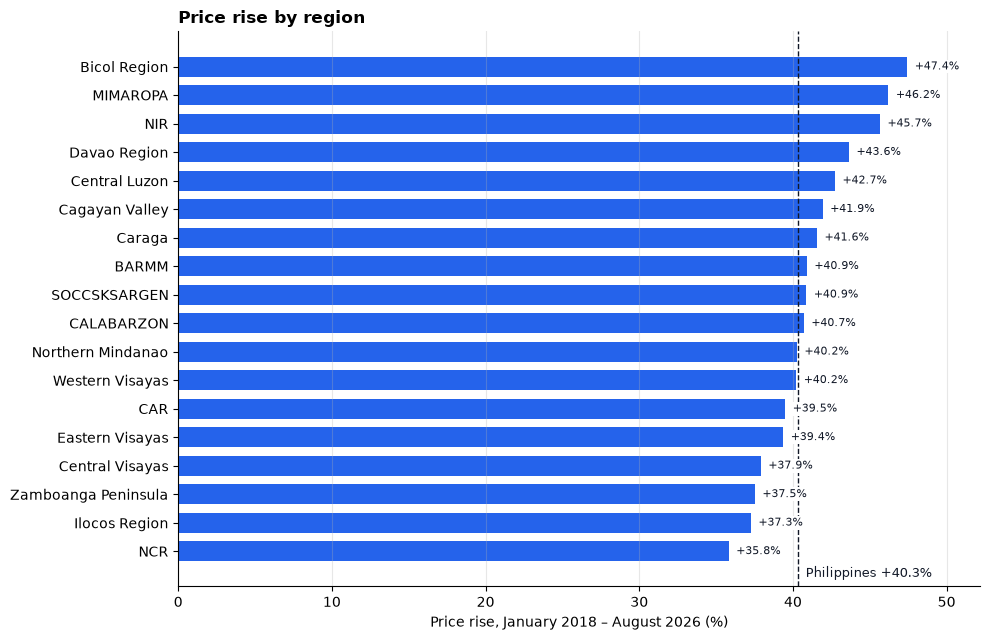

In [14]:
rise = reg_summary["price rise since Jan 2018 (%)"]
national_rise = rise["PHILIPPINES"]
order = rise.drop("PHILIPPINES").sort_values()

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(order.index, order.values, color=COLORS["cpi"], height=0.7)
ax.axvline(national_rise, color=INK, ls="--", lw=1)
ax.text(national_rise + 0.5, -0.9, f"Philippines +{national_rise:.1f}%", fontsize=9, color=INK)
for bar, v in zip(bars, order.values):
    ax.text(v + 0.5, bar.get_y() + bar.get_height() / 2, f"+{v:.1f}%", va="center", fontsize=8, color=INK, bbox=LABEL_BOX)
ax.set_xlim(0, order.max() * 1.1)
ax.set_xlabel("Price rise, January 2018 – August 2026 (%)")
ax.set_title("Price rise by region", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "21_regional_price_rise")

Average gap between the highest- and lowest-inflation region, by year:
date
2019   3.92
2020   3.32
2021   5.28
2022   4.28
2023   4.06
2024   2.92
2025   4.18
2026   5.41


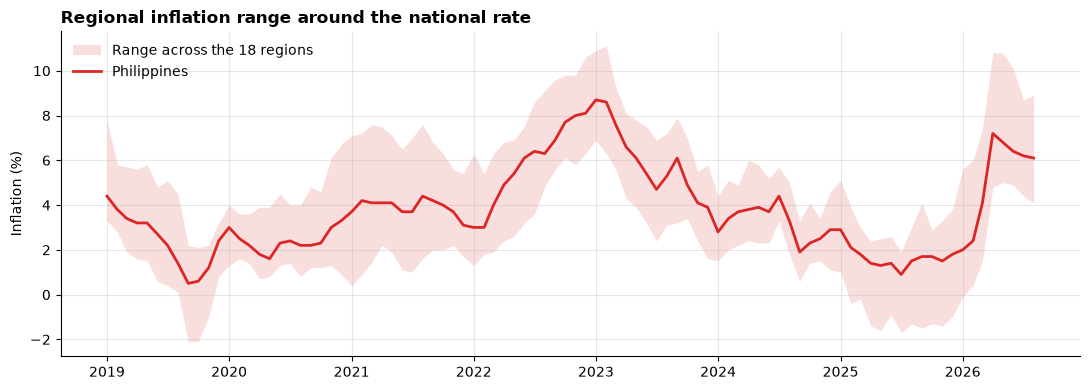

In [15]:
spread = pd.DataFrame({
    "lowest region (%)": reg_inf[regions].min(axis=1),
    "highest region (%)": reg_inf[regions].max(axis=1),
})
spread["gap (points)"] = spread["highest region (%)"] - spread["lowest region (%)"]
print("Average gap between the highest- and lowest-inflation region, by year:")
print(spread["gap (points)"].groupby(spread.index.year).mean().round(2).to_string())

fig, ax = plt.subplots()
ax.fill_between(spread.index, spread["lowest region (%)"], spread["highest region (%)"],
                color=COLORS["inflation"], alpha=0.15, lw=0, label="Range across the 18 regions")
ax.plot(inf.index, inf, color=COLORS["inflation"], label="Philippines")
ax.set_ylabel("Inflation (%)")
ax.set_title("Regional inflation range around the national rate", loc="left", fontweight="bold")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
save(fig, "22_regional_inflation_range")

In [16]:
latest = data.get_regional_comparison("inflation")
latest["region"] = latest["region"].map(short)
print(f"{latest.attrs['date']:%B %Y}, national inflation {latest.attrs['national']:.1f}%")
latest

August 2026, national inflation 6.1%


,rank,region,value,difference_from_national
0,1,Caraga,8.90,2.80
1,2,Davao Region,8.90,2.80
2,3,BARMM,8.80,2.70
3,4,Eastern Visayas,8.40,2.30
4,5,Western Visayas,8.40,2.30
5,6,Central Visayas,8.10,2.00
6,7,Bicol Region,7.70,1.60
7,8,Zamboanga Peninsula,7.60,1.50
8,9,SOCCSKSARGEN,7.60,1.50
9,10,CAR,6.80,0.70


## 6. Household finances (FIES 2023) as context

FIES is a single 2023 snapshot of average annual income, expenditure, and savings per family, in thousand pesos. It cannot show trends, so it is used here only to put the price changes in household terms.

In [17]:
fies = data.get_fies_by_decile()
deciles = fies[fies["decile"] != "All Income Groups"].copy()
deciles["label"] = deciles["decile"].astype(str).str.replace(" Decile", "")
all_groups = fies[fies["decile"] == "All Income Groups"].iloc[0]
print(f"All families: income {all_groups.income:.1f}k, expenditure {all_groups.expenditure:.1f}k, "
      f"savings {all_groups.savings:.1f}k ({all_groups.savings_rate:.1f}% of income)")
print(f"Tenth vs. first decile income: {deciles.income.iloc[-1] / deciles.income.iloc[0]:.1f}x")
deciles[["decile", "income", "expenditure", "savings", "savings_rate"]].set_index("decile")

All families: income 314.8k, expenditure 230.0k, savings 84.8k (26.9% of income)
Tenth vs. first decile income: 6.2x


,income,expenditure,savings,savings_rate
decile,,,,
First Decile,127.70,113.96,13.74,10.76
Second Decile,162.75,137.86,24.89,15.29
Third Decile,185.77,153.73,32.04,17.25
Fourth Decile,214.95,174.33,40.62,18.90
Fifth Decile,242.50,192.68,49.82,20.54
Sixth Decile,275.12,213.46,61.66,22.41
Seventh Decile,313.49,237.28,76.21,24.31
Eighth Decile,370.97,270.86,100.12,26.99
Ninth Decile,456.81,319.38,137.43,30.08


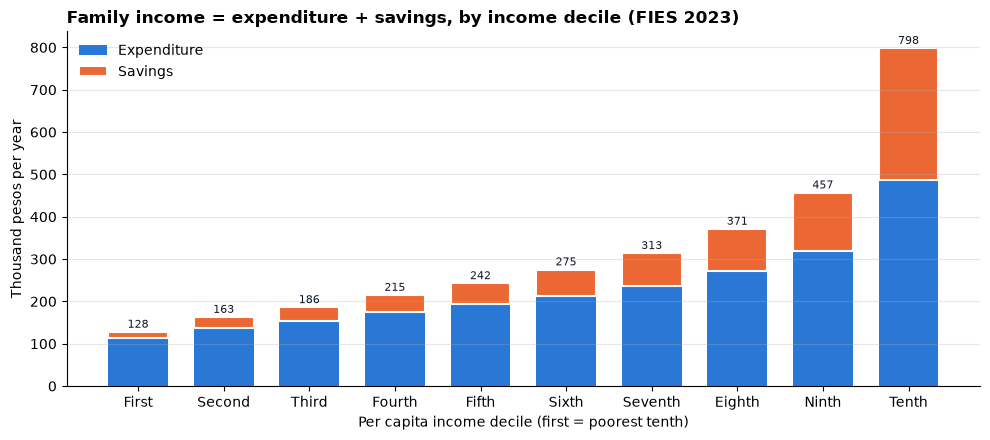

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(deciles))
ax.bar(x, deciles["expenditure"], color=PART_COLORS[0], width=0.7, label="Expenditure")
ax.bar(x, deciles["savings"], bottom=deciles["expenditure"], color=PART_COLORS[1], width=0.7,
       label="Savings", edgecolor="white", linewidth=1.5)
for xi, total in zip(x, deciles["income"]):
    ax.text(xi, total + 10, f"{total:.0f}", ha="center", fontsize=8, color=INK)
ax.set_xticks(x, deciles["label"])
ax.set_xlabel("Per capita income decile (first = poorest tenth)")
ax.set_ylabel("Thousand pesos per year")
ax.set_title("Family income = expenditure + savings, by income decile (FIES 2023)", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
save(fig, "23_fies_by_decile")

### 6.1 Savings margin against the price rise since 2023

An illustration, not a forecast: it compares each decile's 2023 savings (as a share of its spending) with how much prices have risen since 2023. If a family's income had not risen and it bought the same things, a price rise larger than its savings margin would leave it spending more than it earns. Using shares keeps the comparison independent of the price basis of the FIES amounts.

National CPI: 2023 average 122.2 -> Aug 2026 136.4 (+11.6%)


decile,First Decile,Second Decile,Third Decile,Fourth Decile,Fifth Decile,Sixth Decile,Seventh Decile,Eighth Decile,Ninth Decile,Tenth Decile
"savings, % of spending",12.06,18.05,20.84,23.30,25.86,28.89,32.12,36.96,43.03,64.11


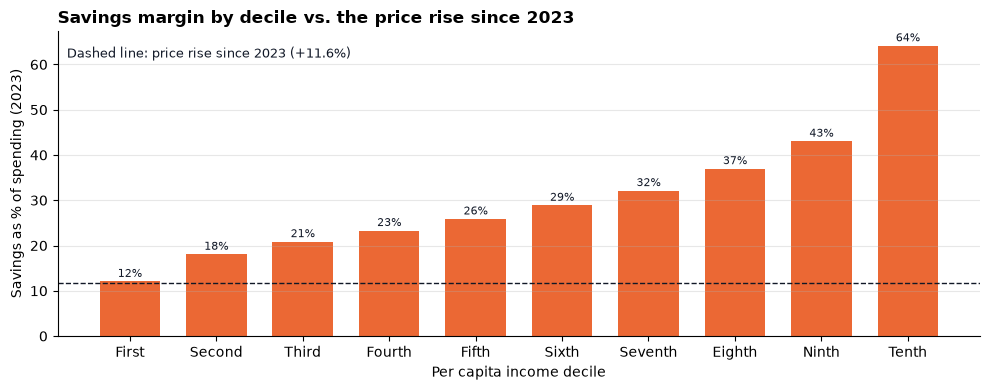

In [19]:
price_rise_since_2023 = (cpi.iloc[-1] / cpi["2023"].mean() - 1) * 100
deciles["savings, % of spending"] = deciles["savings"] / deciles["expenditure"] * 100
print(f"National CPI: 2023 average {cpi['2023'].mean():.1f} -> Aug 2026 {cpi.iloc[-1]:.1f} "
      f"(+{price_rise_since_2023:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x, deciles["savings, % of spending"], color=PART_COLORS[1], width=0.7)
ax.axhline(price_rise_since_2023, color=INK, ls="--", lw=1)
ax.text(0.01, 0.95, f"Dashed line: price rise since 2023 (+{price_rise_since_2023:.1f}%)",
        transform=ax.transAxes, va="top", fontsize=9, color=INK)
for xi, v in zip(x, deciles["savings, % of spending"]):
    ax.text(xi, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=INK)
ax.set_xticks(x, deciles["label"])
ax.set_xlabel("Per capita income decile")
ax.set_ylabel("Savings as % of spending (2023)")
ax.set_title("Savings margin by decile vs. the price rise since 2023", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "24_fies_savings_margin")
deciles.set_index("decile")[["savings, % of spending"]].T

In [20]:
first = data.get_fies_by_region("First Decile")
first["region"] = first["area"].map(short)
print("Poorest tenth: savings as % of income, by region (lowest first)")
print(first.sort_values("savings_rate")[["region", "income", "savings", "savings_rate"]].round(1).to_string(index=False))

negative = data.get_fies().query("savings < 0")
print(f"\nArea-decile groups with negative average savings: {len(negative)} "
      f"(all provinces/cities; {(negative['decile'] == 'First Decile').sum()} in the first decile)")

regional = data.get_fies_by_region().set_index("area")
regional_rise = (reg_cpi[regions].iloc[-1] / reg_cpi[regions].iloc[0] - 1) * 100
r = regional["income"].corr(regional_rise)
print(f"Correlation across the 18 regions between 2023 average income and price rise since Jan 2018: r = {r:.2f}")

Poorest tenth: savings as % of income, by region (lowest first)
             region  income  savings  savings_rate
       SOCCSKSARGEN  100.40     0.70          0.70
  Northern Mindanao   80.90     2.30          2.80
                NIR   99.70     4.20          4.20
             Caraga  116.00     4.90          4.20
              BARMM  126.10     5.90          4.70
                NCR  231.80    12.40          5.30
      Central Luzon  178.10     9.70          5.40
                CAR  157.40    10.10          6.40
    Western Visayas  133.50     9.00          6.80
         CALABARZON  167.00    14.40          8.60
Zamboanga Peninsula  104.60     9.20          8.80
    Eastern Visayas  114.30    10.50          9.20
           MIMAROPA  103.70    12.10         11.70
     Cagayan Valley  139.70    18.00         12.90
    Central Visayas  131.70    20.00         15.20
       Bicol Region  126.70    19.80         15.70
      Ilocos Region  142.00    22.60         15.90
       Davao Regio

## 7. Summary of findings

**National trends (sections 2–3)**
- Prices rose **40.3%** from January 2018 to August 2026 (CPI 97.2 → 136.4). The peso's purchasing power fell to **0.73**: a peso now buys about **27% less** than in 2018.
- Inflation averaged 3.8% but moved in five phases: it eased to a low of **0.5%** (September 2019), stayed low to moderate through 2020–2021, surged to a peak of **8.7%** (January 2023), eased to **0.9%** (July 2025), and then rose again, jumping from 4.1% in March to **7.2%** in April 2026 and staying above 6% through August.
- 2022 and 2023 were the high-inflation years (averages 5.8% and 6.0%); 2025 was the lowest (1.7%).

**Commodity groups (section 4)**
- **Alcoholic beverages and tobacco** rose the most by far, **+113%** since January 2018, more than double any other group.
- **Transport** (+52%), **restaurants** (+45%), **financial services** (+42%), and **food** (+42%) rose faster than all items (+40%). **Information and communication** barely changed (+5%).
- During the 2022–2023 surge (January 2022 – January 2023), transport ran hottest (12.7% average), followed by financial services (10.0%) and alcohol and tobacco (8.1%); housing and utilities (6.6%) and food (6.2%) were close to the overall 6.0%.
- The **April 2026 jump** was led by transport, whose inflation rose 11.5 points in one month (to 21.4%, its highest in the period), followed by housing and utilities (+3.5 points) and food (+3.1 points).

**Regions (section 5)**
- Price rises since January 2018 ranged from **+35.8% in NCR** to **+47.4% in Bicol**. MIMAROPA (+46.2%) and NIR (+45.7%) were also among the highest; Ilocos, Zamboanga Peninsula, and Central Visayas were among the lowest after NCR.
- Central Visayas and NCR were most often among the three lowest-inflation regions (35 and 28 of 92 months); MIMAROPA and Bicol were most often among the three highest (31 and 27 months). In August 2026 NCR is lowest (4.1%) and Caraga and Davao Region highest (8.9%).
- Regions moved apart most in 2021 and in 2026: the average gap between the highest and lowest regional inflation rate was about 5.3–5.4 points, against about 3 points in 2024.

**Household context (section 6)**
- In 2023 the richest tenth of families earned **6.2 times** as much as the poorest tenth and saved 39% of income; the poorest tenth saved 11%.
- Since 2023, prices have risen **11.6%**. For the poorest tenth, that is about the size of their whole 2023 savings margin (savings equal to 12% of spending): without income growth, the price rise alone would have absorbed it. Every other decile had a margin of at least 18%.
- Among the poorest tenth, savings were thinnest in SOCCSKSARGEN (0.7% of income), Northern Mindanao (2.8%), NIR, and Caraga (4.2%); 27 province-decile groups had negative average savings in 2023.
- Lower-income regions tended to see slightly larger price rises (r = −0.37 across 18 regions), a weak pattern on few data points.

## 8. Limitations

1. **Descriptive only.** The data shows when and where prices changed, not why. Explanations (for example tax or fuel-price changes) need sources outside this dataset and are not claimed here.
2. **No basket weights.** Commodity groups are compared by their own price changes, not by their contribution to overall inflation.
3. **Phases are a reading of the series.** The boundaries follow inflation's turning points and are not an official classification.
4. **Regional indices measure change, not price levels.** Each region's CPI is relative to its own 2018 level, so a higher index means faster price growth, not higher prices.
5. **FIES is one year.** Household income, expenditure, and savings are a 2023 snapshot; section 6.1 is an illustration under stated assumptions, not an estimate of current household finances.